<a href="https://colab.research.google.com/github/nikita082000/DTEY/blob/%D0%9C%D0%9D/%D0%9B%D0%A0_2_1_%D0%9D%D1%96%D0%BA%D0%B8%D1%82%D0%B5%D0%BD%D0%BA%D0%BE__4_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Лабораторна робота 2. Нікитенко, 4-9

*   List item
*   List item



---



# Завдання 1

**Був присутній на парі**

Обробка та нааліз даних про ВВП країн. Датасет було отримано з Вікіпедії з використанням бібілотеки Pandas.

1. Вивести перші 5 рядків датасета

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

from io import StringIO

url = "https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)"

headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(url, headers=headers)
response.raise_for_status()

tables = pd.read_html(
    StringIO(response.text),
    match="Country/Territory"
)
df = tables[0]

df.head()

,Country/Territory,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
0,World,126295331,118350166,111565144
1,United States,32383920,30769700,29298000
2,China[n 1],20851593,19498039,18743802
3,Germany,5452858,5050923,4659929
4,Japan,4379253,4435163,4026211


In [33]:
df.columns

Index(['Country/Territory', 'IMF (2026)[1]', 'World Bank (2025)[6]',
       'United Nations (2024)[7]'],
      dtype='object')

2.	Визначити розмір датасета.

In [34]:
print("Розмір датасета:", df.shape)
print("Кількість рядків:", df.shape[0])
print("Кількість стовпців:", df.shape[1])

Розмір датасета: (222, 4)
Кількість рядків: 222
Кількість стовпців: 4


# Датасет містить 4 стовпці, і всі вони використовуються в подальшому аналізі, тому зайві стовпці відсутні.

 3.	Визначити оптимальну кількість стовпців (видалити зайві, на власний розсуд).

4.	Замініть у таблиці значення "—" на значення NaN. Перевірити наявність пропущених значень. При наявності, замінити пропущені значення на середнє значення.

In [35]:
df.replace(["—", "—N/a"], np.nan, inplace=True)

In [36]:
print("Кількість пропущених значень:")
print(df.isna().sum())

Кількість пропущених значень:
Country/Territory            0
IMF (2026)[1]               24
World Bank (2025)[6]         7
United Nations (2024)[7]     9
dtype: int64


In [38]:
df.isna().sum()

,0
Country/Territory,0
IMF (2026)[1],24
World Bank (2025)[6],7
United Nations (2024)[7],9


In [41]:
numeric_columns = df.columns[1:]

df[numeric_columns] = df[numeric_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

In [45]:
df[numeric_columns] = df[numeric_columns].fillna(
    df[numeric_columns].mean()
)

print("Пропущені значення після заповнення:")
print(df.isna().sum())

Пропущені значення після заповнення:
Country/Territory           0
IMF (2026)[1]               0
World Bank (2025)[6]        0
United Nations (2024)[7]    0
dtype: int64


5. Ще раз вивести датасет

In [46]:
df

,Country/Territory,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
0,World,1.262953e+08,1.183502e+08,111565144.0
1,United States,3.238392e+07,3.076970e+07,29298000.0
2,China[n 1],2.085159e+07,1.949804e+07,18743802.0
3,Germany,5.452858e+06,5.050923e+06,4659929.0
4,Japan,4.379253e+06,4.435163e+06,4026211.0
...,...,...,...,...
217,Palau,3.770000e+02,3.450000e+02,310.0
218,Marshall Islands,3.420000e+02,3.080000e+02,281.0
219,Nauru,1.960000e+02,1.760000e+02,187.0
220,Montserrat,1.319229e+06,1.255590e+06,81.0


6.	Перевірити наявність дублікатів. При наявності видалити дублікати.

In [49]:
print("Кількість дублікатів:", df.duplicated().sum())





Кількість дублікатів: 0


In [50]:
df.drop_duplicates(inplace=True)

In [51]:
print("Кількість дублікатів після видалення:", df.duplicated().sum())

Кількість дублікатів після видалення: 0


7.	Вивести описову статистику датасету describe()

In [52]:
df.describe()

,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
count,2.220000e+02,2.220000e+02,2.220000e+02
mean,1.319229e+06,1.255590e+06,1.043818e+06
std,8.838876e+06,8.288461e+06,7.830341e+06
min,6.500000e+01,5.700000e+01,5.600000e+01
25%,1.932375e+04,2.003400e+04,9.170750e+03
50%,1.039745e+05,9.986350e+04,4.322450e+04
75%,7.726678e+05,1.041520e+06,3.048545e+05
max,1.262953e+08,1.183502e+08,1.115651e+08


8. Визначте відхилення (різницю) між показниками IMF (2026) та World Bank (2025) для кожної країни. У яких країнах ці показники найбільше відрізняються (дати відповідь)?

In [58]:
# Рядок World був виключений із порівняння країн, оскільки він є зайвим показником.
countries = df[df["Country/Territory"] != "World"].copy()

countries["Difference"] = (
    countries["IMF (2026)[1]"]
    - countries["World Bank (2025)[6]"]
)

countries["Abs_Difference"] = countries["Difference"].abs()

countries[
    ["Country/Territory", "Difference", "Abs_Difference"]
].sort_values("Abs_Difference", ascending=False).head(10)

max_diff_country = countries.loc[
    countries["Abs_Difference"].idxmax()
]

print("Найбільша різниця:")
print("Країна:", max_diff_country["Country/Territory"])
print("Різниця:", max_diff_country["Difference"])

Найбільша різниця:
Країна: United States
Різниця: 1614220.0


9.	Обчисліть кореляцію між показниками IMF (2026), World Bank (2025) та United Nations (2024). Які пари змінних мають найвищу кореляцію?

In [59]:
gdp_columns = [
    "IMF (2026)[1]",
    "World Bank (2025)[6]",
    "United Nations (2024)[7]"
]

correlation = countries[gdp_columns].corr()

correlation

,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
IMF (2026)[1],1.000000,0.994577,0.989369
World Bank (2025)[6],0.994577,1.000000,0.987916
United Nations (2024)[7],0.989369,0.987916,1.000000


# Найвища кореляція спостерігається між показниками IMF (2026) та World Bank (2025) і становить приблизно 0.995

Обчислити середнє значення за стовпцями

In [60]:
mean_values = countries[gdp_columns].mean()

print(mean_values)

IMF (2026)[1]               753726.523205
World Bank (2025)[6]        725750.713964
United Nations (2024)[7]    543721.719202
dtype: float64


11.	Обчисліть стандартне відхилення показників для кожної країни. Яка країна має найвищу варіативність у показниках між роками?

In [63]:
countries["Std_Deviation"] = countries[gdp_columns].std(axis=1)

countries[
    ["Country/Territory", "Std_Deviation"]
].sort_values("Std_Deviation", ascending=False).head(10)

max_std_country = countries.loc[
    countries["Std_Deviation"].idxmax()
]

print("Найвища варіативність:")
print("Країна:", max_std_country["Country/Territory"])
print("Стандартне відхилення:", max_std_country["Std_Deviation"])

Найвища варіативність:
Країна: United States
Стандартне відхилення: 1543508.4140144275


12.	Визначення країни з найвищим та найнижчим показниками: Знайдіть країну з найвищим та найнижчим показниками у кожному з років (IMF (2026), World Bank (2025), United Nations (2024)).

In [64]:
for column in gdp_columns:
    max_row = countries.loc[countries[column].idxmax()]
    min_row = countries.loc[countries[column].idxmin()]

    print("\n", column)

    print(
        "Найвище:",
        max_row["Country/Territory"],
        "-",
        max_row[column]
    )

    print(
        "Найнижче:",
        min_row["Country/Territory"],
        "-",
        min_row[column]
    )


 IMF (2026)[1]
Найвище: United States - 32383920.0
Найнижче: Tuvalu - 65.0

 World Bank (2025)[6]
Найвище: United States - 30769700.0
Найнижче: Tuvalu - 57.0

 United Nations (2024)[7]
Найвище: United States - 29298000.0
Найнижче: Tuvalu - 56.0


13.	Побудуйте гістограму для розподілу показників IMF (2026) серед всіх країн. Який вигляд має розподіл? Чи є країни, що виділяються?

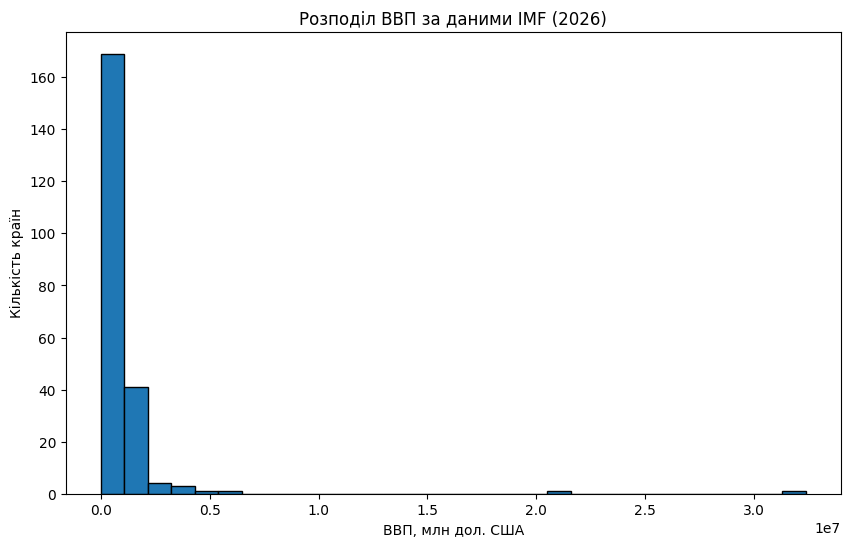

In [67]:
plt.figure(figsize=(10, 6))

plt.hist(
    countries["IMF (2026)[1]"],
    bins=30,
    edgecolor="black"
)

plt.xlabel("ВВП, млн дол. США")
plt.ylabel("Кількість країн")
plt.title("Розподіл ВВП за даними IMF (2026)")

plt.show()



# Розподіл ВВП має сильну правосторонню асиметрію. Більшість країн мають відносно невеликі значення ВВП, тоді як кілька країн мають значно вищі показники. Особливо виділяються США та Китай.

14.	Розрахуйте частку кожної країни в загальному значенні для кожного року (IMF (2026), World Bank (2025), United Nations (2024)).
 Як змінюються частки країн з часом (дати відповідь)?

In [70]:
countries["Share_UN"] = (
    countries["United Nations (2024)[7]"]
    / countries["United Nations (2024)[7]"].sum()
    * 100
)

countries["Share_WB"] = (
    countries["World Bank (2025)[6]"]
    / countries["World Bank (2025)[6]"].sum()
    * 100
)

countries["Share_IMF"] = (
    countries["IMF (2026)[1]"]
    / countries["IMF (2026)[1]"].sum()
    * 100
)

countries[
    [
        "Country/Territory",
        "Share_UN",
        "Share_WB",
        "Share_IMF"
    ]
].sort_values("Share_IMF", ascending=False)


,Country/Territory,Share_UN,Share_WB,Share_IMF
1,United States,24.381983,19.184192,19.441212
2,China[n 1],15.598712,12.156574,12.517949
3,Germany,3.878023,3.149133,3.273544
4,Japan,3.350639,2.765221,2.629020
5,United Kingdom,3.067414,2.495521,2.560307
...,...,...,...,...
216,Kiribati,0.000285,0.000218,0.000241
217,Palau,0.000258,0.000215,0.000226
218,Marshall Islands,0.000234,0.000192,0.000205
219,Nauru,0.000156,0.000110,0.000118


# Частки країн у загальному ВВП змінюються нерівномірно. У частини найбільших економік частка збільшується, в інших — зменшується або залишається приблизно стабільною.

15.	Візуалізуйте зміни в показниках для кожної країни за три роки на графіку. Які країни показують стабільне зростання або спад (дати відповідь)?

Країни зі стабільним зростанням:
['United States', 'China[n 1]', 'Germany', 'United Kingdom', 'India', 'France', 'Italy', 'Russia', 'Brazil', 'Canada', 'Spain', 'Turkey', 'Indonesia', 'Netherlands', 'Saudi Arabia', 'Switzerland', 'Poland', 'Ireland', 'Belgium', 'Sweden', 'Israel', 'Argentina', 'Singapore', 'Austria', 'Norway', 'Thailand', 'Colombia', 'Vietnam', 'Malaysia', 'Philippines', 'Bangladesh', 'Denmark', 'Romania', 'South Africa', 'Hong Kong[n 4]', 'Czech Republic', 'Egypt', 'Chile', 'Pakistan', 'Peru', 'Portugal', 'Nigeria', 'Kazakhstan', 'Finland', 'Algeria', 'Greece', 'New Zealand', 'Hungary', 'Cuba', 'Ukraine[n 5]', 'Morocco', 'Uzbekistan', 'Slovakia', 'Angola', 'Bulgaria', 'Kenya', 'Ecuador', 'Dominican Republic', 'Guatemala', 'DR Congo', 'Ghana', 'Oman', 'Croatia', 'Ivory Coast', 'Serbia', 'Luxembourg', 'Costa Rica', 'Sri Lanka', 'Lithuania', 'Belarus', 'Uruguay', 'Panama', 'Tanzania[n 6]', 'Slovenia', 'Myanmar', 'Bolivia', 'Azerbaijan', 'Uganda', 'Cameroon', 'Jordan', 'T

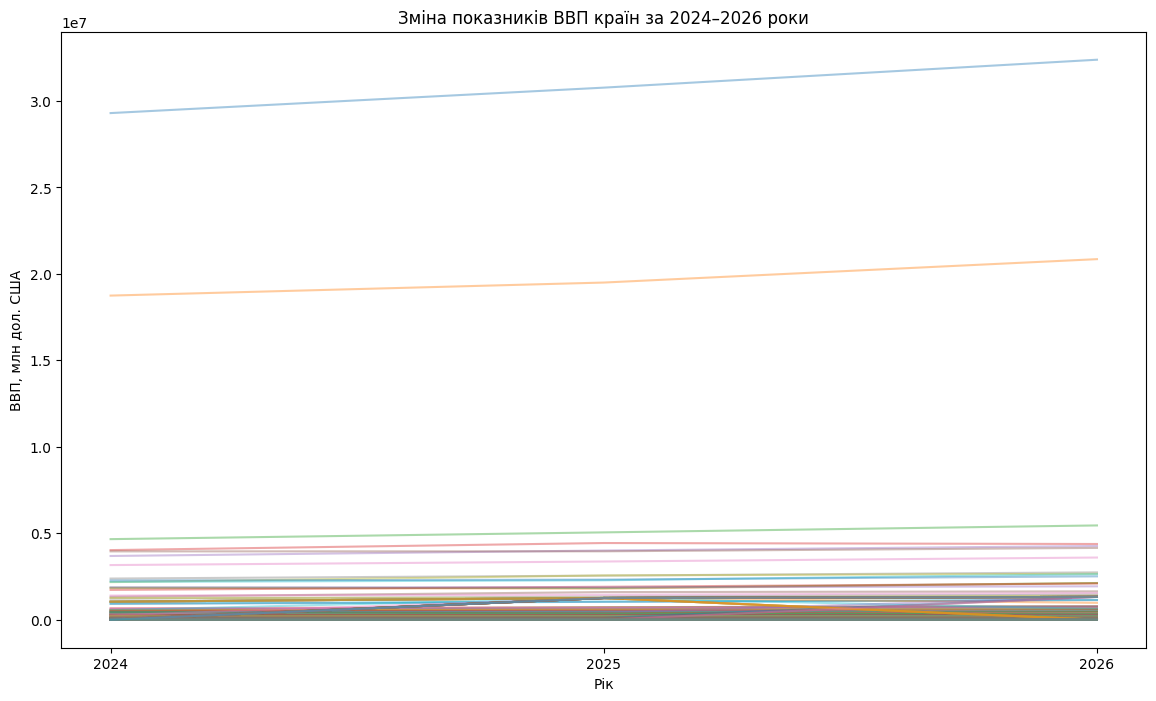

In [72]:
growth = countries[
    (countries["United Nations (2024)[7]"] <
     countries["World Bank (2025)[6]"])
    &
    (countries["World Bank (2025)[6]"] <
     countries["IMF (2026)[1]"])
]

print("Країни зі стабільним зростанням:")
print(growth["Country/Territory"].tolist())

decline = countries[
    (countries["United Nations (2024)[7]"] >
     countries["World Bank (2025)[6]"])
    &
    (countries["World Bank (2025)[6]"] >
     countries["IMF (2026)[1]"])
]

print("Країни зі стабільним спадом:")
print(decline["Country/Territory"].tolist())

plot_data = countries.set_index("Country/Territory")[
    [
        "United Nations (2024)[7]",
        "World Bank (2025)[6]",
        "IMF (2026)[1]"
    ]
].T

plot_data.index = [2024, 2025, 2026]

plt.figure(figsize=(14, 8))

for country in plot_data.columns:
    plt.plot(
        plot_data.index,
        plot_data[country],
        alpha=0.4
    )

plt.xlabel("Рік")
plt.ylabel("ВВП, млн дол. США")
plt.title("Зміна показників ВВП країн за 2024–2026 роки")
plt.xticks([2024, 2025, 2026])

plt.show()